# Section 1 : Chargement des données
un pipeline ELT signifie Extract, Load, Transform (Extraire, Charger, Transformer). C’est un acronyme issu de l’ingénierie des données (data engineering).

In [42]:
import pandas as pd

df = pd.read_csv('data/online_retail_II.csv', encoding='ISO-8859-1')

# Afficher les dimensions (lignes, colonnes)
print("Dimensions :", df.shape)

# Afficher les 5 premières lignes
df.head()

Dimensions : (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


# Section 2 : Nettoyage et préparation

In [43]:
#Copier de travail pour conserver les données originales
df_clean = df.copy()

In [44]:
#Afficher les types de données de chaque colonne
df_clean.dtypes

Invoice            str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
Price          float64
Customer ID    float64
Country            str
dtype: object

In [45]:
# Nombre de valeurs manquantes par colonne
df_clean.isna().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [46]:
#Afficher les lignes ou les colonnes contiennent des valeurs manquantes (description)
df_clean[df_clean["Description"].isna()].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom
6378,489882,35751C,NaN,12,2009-12-02 16:22:00,0.0,NaN,United Kingdom
6555,489898,79323G,NaN,954,2009-12-03 09:40:00,0.0,NaN,United Kingdom
6576,489901,21098,NaN,-200,2009-12-03 09:47:00,0.0,NaN,United Kingdom
6581,489903,21166,NaN,48,2009-12-03 09:57:00,0.0,NaN,United Kingdom


In [47]:
#Afficher les lignes ou les colonnes contiennent des valeurs manquantes (customer ID)
df_clean[df_clean["Customer ID"].isna()].head(10)
print(len(df_clean[df_clean["Customer ID"].isna()]))

243007


In [48]:
# Filtrer les lignes avec des valeurs manquantes dans la colonne "Customer ID"
df_clients = df_clean[df_clean["Customer ID"].notna()]
print(len(df_clients))

824364


In [49]:
print("Dimensions après suppression des lignes avec Customer ID manquant :", df_clients.shape)

Dimensions après suppression des lignes avec Customer ID manquant : (824364, 8)


In [50]:
df_clean = df.dropna()
print(df_clean.shape)

(824364, 8)


In [51]:
# Filtrage des lignes avec des quantités négatives
df_clean = df_clean[df_clean["Quantity"] >= 0]
print("Dimensions après suppression des lignes avec des quantités négatives :", df_clean.shape)

Dimensions après suppression des lignes avec des quantités négatives : (805620, 8)


In [52]:
# Enregistrer le DataFrame nettoyé dans un nouveau fichier CSV
df_clean.to_csv('online_retail_cleaned.csv', index=False, encoding='ISO-8859-1')

In [53]:
# Convertir InvoiceDate en véritable type date
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'], dayfirst=True, errors='coerce')
print("Types de données après conversion de InvoiceDate :", df_clean.dtypes)

Types de données après conversion de InvoiceDate : Invoice                   str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object


In [13]:
# Enregistrer le DataFrame nettoyé dans un nouveau fichier CSV
df_clean.to_csv('online_retail_cleaned.csv', index=False, encoding='ISO-8859-1')

In [14]:
print("Dimensions :", df_clean.shape)
# Afficher les 5 premières lignes
df_clean.head()
df_clean.dtypes

Dimensions : (805620, 8)


Invoice                   str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

# Section 3 : Analyse exploratoire

In [15]:
# Examiner les lignes dont le prix est nul
df_clean[df_clean["Price"] == 0].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-02-12 13:34:00,0.0,16126.0,United Kingdom
6781,489998,48185,DOOR MAT FAIRY CAKE,2,2009-03-12 11:19:00,0.0,15658.0,United Kingdom
16107,490727,M,Manual,1,2009-07-12 16:38:00,0.0,17231.0,United Kingdom
18738,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,2009-08-12 15:25:00,0.0,14108.0,United Kingdom
18739,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,2009-08-12 15:25:00,0.0,14108.0,United Kingdom
32916,492079,85042,ANTIQUE LILY FAIRY LIGHTS,8,NaT,0.0,15070.0,United Kingdom
40101,492760,21143,ANTIQUE GLASS HEART DECORATION,12,NaT,0.0,18071.0,United Kingdom
47126,493761,79320,FLAMINGO LIGHTS,24,2010-06-01 14:54:00,0.0,14258.0,United Kingdom
48342,493899,22355,"CHARLOTTE BAG , SUKI DESIGN",10,2010-08-01 10:43:00,0.0,12417.0,Belgium
57619,494607,21533,RETRO SPOT LARGE MILK JUG,12,NaT,0.0,16858.0,United Kingdom


In [16]:
# Compter ces lignes 
print("Nombre de lignes avec un prix nul :", len(df_clean[df_clean["Price"] == 0]))

Nombre de lignes avec un prix nul : 71


In [17]:
# Calculer le CA pour chaque ligne
df_clean["CA"] = df_clean["Quantity"] * df_clean["Price"]
df_clean.head()


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,CA
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-01-12 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-01-12 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-01-12 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-01-12 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-01-12 07:45:00,1.25,13085.0,United Kingdom,30.0


In [18]:
# Calculer le CA total 
# Ensure the CA column exists before summing it
if "CA" not in df_clean.columns:
    df_clean = df_clean.copy()
    df_clean["CA"] = df_clean["Quantity"].astype(float) * df_clean["Price"].astype(float)

ca_total = df_clean["CA"].sum()
print("end=> CA total :", ca_total)

end=> CA total : 17743429.178000003


In [19]:
# Ajout d'une colonne pour le mois
import pandas as pd

# Reuse the dataframe already loaded in the notebook.
# If it is not available yet, load it from the correct relative path.
if "df" not in globals():
    df = pd.read_csv("data/online_retail_II.csv", encoding="ISO-8859-1")
df_clean = df.copy()
df_clean = df_clean.dropna()
df_clean = df_clean[df_clean["Quantity"] >= 0]

df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"], dayfirst=True, errors="coerce")
df_clean["Mois"] = df_clean["InvoiceDate"].dt.month
print(df_clean.head())

  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  Mois  
0 2009-01-12 07:45:00   6.95      13085.0  United Kingdom   1.0  
1 2009-01-12 07:45:00   6.75      13085.0  United Kingdom   1.0  
2 2009-01-12 07:45:00   6.75      13085.0  United Kingdom   1.0  
3 2009-01-12 07:45:00   2.10      13085.0  United Kingdom   1.0  
4 2009-01-12 07:45:00   1.25      13085.0  United Kingdom   1.0  


In [20]:
df_clean["CA"] = df_clean["Quantity"] * df_clean["Price"]
print(df_clean.head())

  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  Mois     CA  
0 2009-01-12 07:45:00   6.95      13085.0  United Kingdom   1.0   83.4  
1 2009-01-12 07:45:00   6.75      13085.0  United Kingdom   1.0   81.0  
2 2009-01-12 07:45:00   6.75      13085.0  United Kingdom   1.0   81.0  
3 2009-01-12 07:45:00   2.10      13085.0  United Kingdom   1.0  100.8  
4 2009-01-12 07:45:00   1.25      13085.0  United Kingdom   1.0   30.0  


In [21]:
# Le CA par mois 
df_clean.groupby("Mois")["CA"].sum().sort_index()

Mois
1.0     594820.021
2.0     544339.830
3.0     591574.841
4.0     607451.710
5.0     646253.710
6.0     585615.000
7.0     812057.580
8.0     673828.361
9.0     783897.340
10.0    602235.650
11.0    643587.040
12.0    487101.101
Name: CA, dtype: float64

In [22]:
# Calcul des ventes par mois
ventes_par_mois = df_clean.groupby("Mois")["Quantity"].sum().sort_index()
print(ventes_par_mois)

Mois
1.0     345593
2.0     318395
3.0     343979
4.0     369319
5.0     386412
6.0     348701
7.0     453814
8.0     389995
9.0     509775
10.0    319386
11.0    372707
12.0    292258
Name: Quantity, dtype: int64


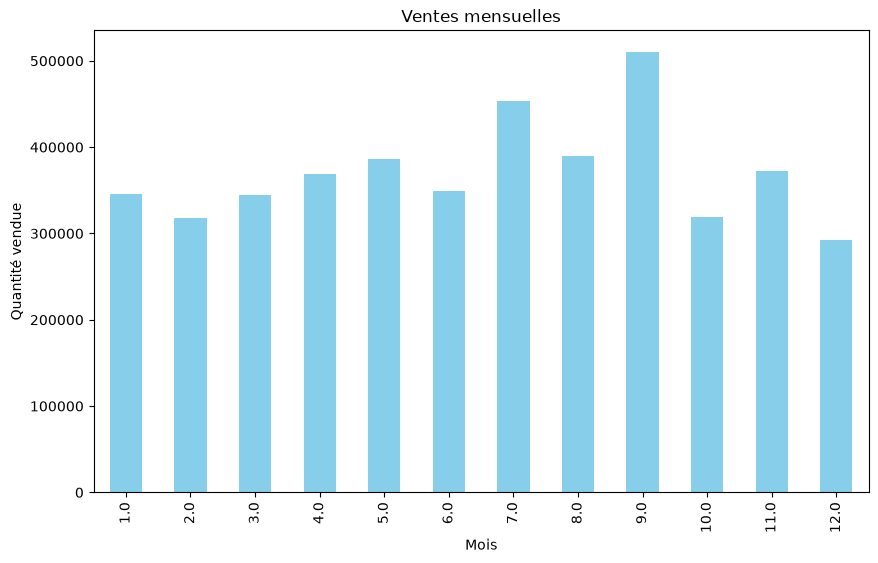

In [23]:
# Visualisation les ventes par mois
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
ventes_par_mois.plot(kind='bar', color='skyblue')
plt.title('Ventes mensuelles')
plt.xlabel('Mois')
plt.ylabel('Quantité vendue')
plt.show()

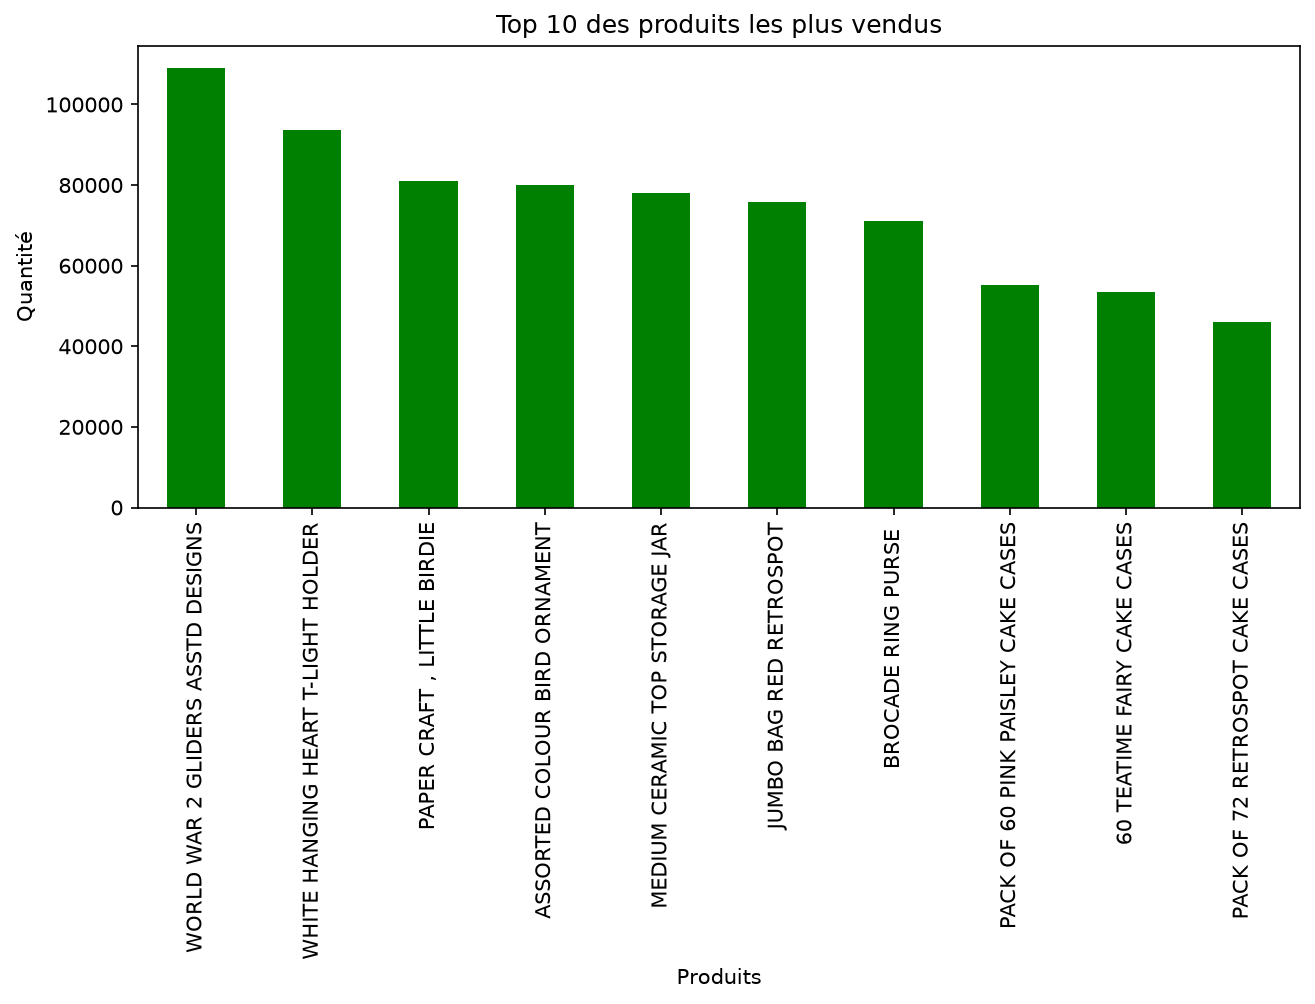

In [24]:
# Regroupement par produit
top_products = df_clean.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

# Visualisation
plt.figure(figsize=(10, 4), dpi=150)
top_products.plot(kind='bar', color='green')
plt.title('Top 10 des produits les plus vendus')
plt.xlabel('Produits')
plt.ylabel('Quantité')
plt.show()

In [25]:
# Répartition géographique
ca_pays = df_clean.groupby("Country")["CA"].sum().sort_values(ascending=False).head(5)
print(ca_pays.head(10))

Country
United Kingdom    1.472315e+07
EIRE              6.216311e+05
Netherlands       5.542323e+05
Germany           4.312625e+05
France            3.552575e+05
Name: CA, dtype: float64


Text(0.5, 1.0, "Chiffre d'affaires par pays")

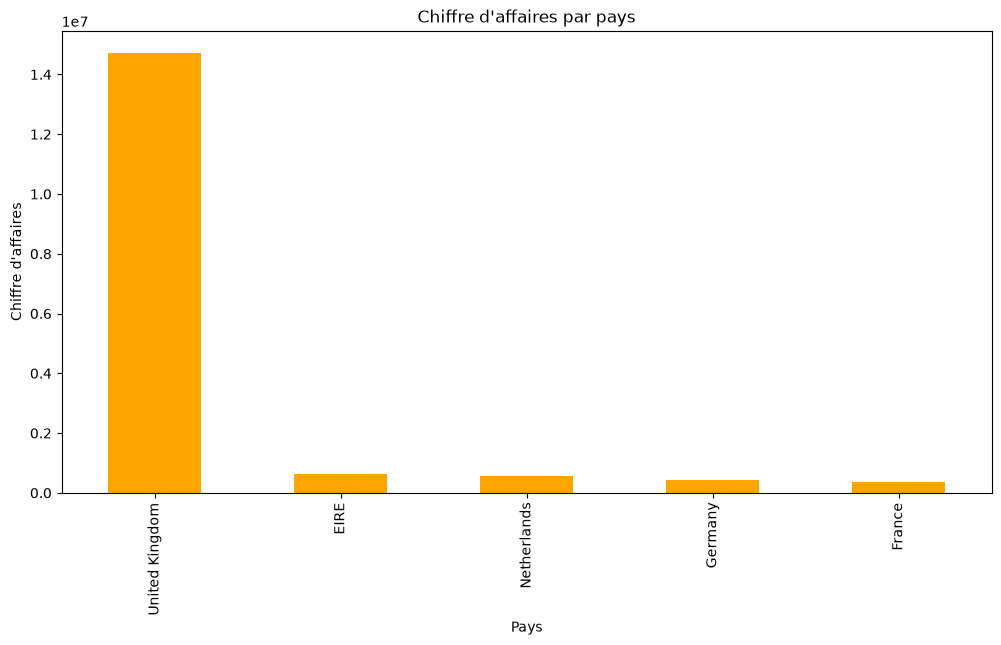

In [26]:
# Visualisation
ca_pays.plot(kind='bar', figsize=(12, 6), color='orange')
plt.xlabel('Pays')
plt.ylabel('Chiffre d\'affaires')
plt.title('Chiffre d\'affaires par pays')

# Section 4 : Segmentation client RFM

In [27]:
# Ajouter une colonne pour le total des ventes
print(df_clean.head())

  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  Mois     CA  
0 2009-01-12 07:45:00   6.95      13085.0  United Kingdom   1.0   83.4  
1 2009-01-12 07:45:00   6.75      13085.0  United Kingdom   1.0   81.0  
2 2009-01-12 07:45:00   6.75      13085.0  United Kingdom   1.0   81.0  
3 2009-01-12 07:45:00   2.10      13085.0  United Kingdom   1.0  100.8  
4 2009-01-12 07:45:00   1.25      13085.0  United Kingdom   1.0   30.0  


In [28]:
# Calculer les revenus par client
top_customers = df_clean.groupby("Customer ID")["CA"].sum().sort_values(ascending=False).head(10)
print(top_customers)

Customer ID
18102.0    608821.65
14646.0    528602.52
14156.0    313946.37
14911.0    295972.63
17450.0    246973.09
13694.0    196482.81
17511.0    175603.55
16446.0    168472.50
16684.0    147142.77
12415.0    144458.37
Name: CA, dtype: float64


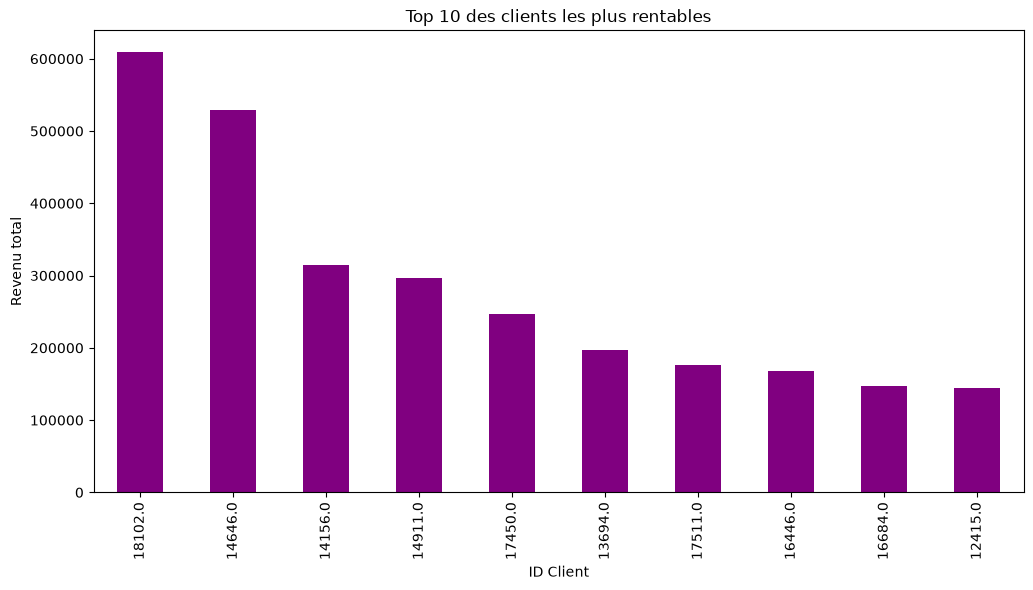

In [29]:
top_customers.plot(kind = 'bar', figsize=(12, 6), color='purple')
plt.title('Top 10 des clients les plus rentables')
plt.xlabel('ID Client')
plt.ylabel('Revenu total')
plt.show()

In [30]:
# 1. Vérifier la date de la toute dernière transaction enregistrée
derniere_date = df_clean['InvoiceDate'].max()
print("Dernière commande dans les données :", derniere_date)

Dernière commande dans les données : 2011-12-10 17:19:00


In [31]:
# 2. Fixer la date de référence au lendemain (+ 1 jour)
date_ref = derniere_date + pd.Timedelta(days=1)
print("Date de référence retenue :", date_ref)

Date de référence retenue : 2011-12-11 17:19:00


In [32]:
# Agrégation par client unique
rfm = df_clean.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (date_ref - x.max()).days,  # Récence : jours écoulés
    'Invoice': 'nunique',                                # Fréquence : nombre de factures distinctes
    'CA': 'sum'                                          # Montant : total dépensé
}).reset_index()
# Renommer les colonnes
rfm.columns = ['Customer ID', 'Recency', 'Frequency', 'Monetary']

# Arrondir le montant à 2 décimales pour la lisibilité
rfm['Monetary'] = rfm['Monetary'].round(2)

# Aperçu des 5 premiers clients
rfm.head()
print(rfm)


      Customer ID  Recency  Frequency  Monetary
0         12346.0    619.0         12  77556.46
1         12347.0     96.0          8   5633.32
2         12348.0    221.0          5   2019.40
3         12349.0      NaN          4   4428.69
4         12350.0    312.0          1    334.40
...           ...      ...        ...       ...
5876      18283.0     61.0         22   2736.65
5877      18284.0    610.0          1    461.68
5878      18285.0      NaN          1    427.00
5879      18286.0      NaN          2   1296.43
5880      18287.0      1.0          7   4182.99

[5881 rows x 4 columns]


In [33]:
print(df_clean['InvoiceDate'].dtype)
print("Nombre de dates manquantes :", df_clean['InvoiceDate'].isna().sum())

datetime64[us]
Nombre de dates manquantes : 469909


In [34]:
# 1. On repart du df initial ou on applique un formatage flexible
df_clean['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='mixed', dayfirst=True)

# 2. Vérification immédiate
print("Type :", df_clean['InvoiceDate'].dtype)
print("Nouvelles dates manquantes :", df_clean['InvoiceDate'].isna().sum())

Type : datetime64[us]
Nouvelles dates manquantes : 0


In [35]:
# 1. Mettre à jour la date de référence
date_ref = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)
print("Nouvelle date de référence :", date_ref)

# 2. Agrégation RFM par client
rfm = df_clean.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (date_ref - x.max()).days,
    'Invoice': 'nunique',
    'CA': 'sum'
}).reset_index()

rfm.columns = ['Customer ID', 'Recency', 'Frequency', 'Monetary']
rfm['Monetary'] = rfm['Monetary'].round(2)

# 3. Vérification des valeurs manquantes
print("Nombre de NaN dans Recency :", rfm['Recency'].isna().sum())

# 4. Aperçu
rfm.head()

#5
print(rfm)

Nouvelle date de référence : 2011-12-11 17:19:00
Nombre de NaN dans Recency : 0
      Customer ID  Recency  Frequency  Monetary
0         12346.0      327         12  77556.46
1         12347.0       41          8   5633.32
2         12348.0       77          5   2019.40
3         12349.0       20          4   4428.69
4         12350.0      312          1    334.40
...           ...      ...        ...       ...
5876      18283.0       11         22   2736.65
5877      18284.0      610          1    461.68
5878      18285.0      662          1    427.00
5879      18286.0      478          2   1296.43
5880      18287.0        1          7   4182.99

[5881 rows x 4 columns]


In [36]:
# 1. Calcul des scores (1 à 5)
rfm['R_score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1])
rfm['F_score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
rfm['M_score'] = pd.qcut(rfm['Monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])

# 2. Concaténer le score global (ex: "555", "111")
rfm['RFM_Score'] = rfm['R_score'].astype(str) + rfm['F_score'].astype(str) + rfm['M_score'].astype(str)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Score
0,12346.0,327,12,77556.46,2,5,5,255
1,12347.0,41,8,5633.32,4,4,5,445
2,12348.0,77,5,2019.40,3,4,4,344
3,12349.0,20,4,4428.69,5,3,5,535
4,12350.0,312,1,334.40,2,1,2,212


In [37]:
# 3. Attribution des segments métiers
def classifier_client(row):
    r = int(row['R_score'])
    f = int(row['F_score'])
    
    if r >= 4 and f >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3:
        return 'Clients fidèles'
    elif r >= 4 and f <= 2:
        return 'Nouveaux clients'
    elif r <= 2 and f >= 3:
        return 'Clients à risque'
    elif r <= 2 and f <= 2:
        return 'Clients perdus'
    else:
        return 'Clients prometteurs'

rfm['Segment'] = rfm.apply(classifier_client, axis=1)

# 4. Affichage de la répartition
print(rfm['Segment'].value_counts())
rfm.head()

Segment
Clients perdus         1527
Champions              1515
Clients fidèles        1193
Clients à risque        820
Nouveaux clients        431
Clients prometteurs     395
Name: count, dtype: int64


,Customer ID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Score,Segment
0,12346.0,327,12,77556.46,2,5,5,255,Clients à risque
1,12347.0,41,8,5633.32,4,4,5,445,Champions
2,12348.0,77,5,2019.40,3,4,4,344,Clients fidèles
3,12349.0,20,4,4428.69,5,3,5,535,Clients fidèles
4,12350.0,312,1,334.40,2,1,2,212,Clients perdus


In [38]:
# Moyennes et volume par segment
resume_segments = rfm.groupby('Segment').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(1)

# Renommer les colonnes pour la lisibilité
resume_segments.columns = ['Récence moy (jours)', 'Fréquence moy (achats)', 'Panier total moy (£)', 'Nombre de clients']
resume_segments.sort_values(by='Panier total moy (£)', ascending=False)

,Récence moy (jours),Fréquence moy (achats),Panier total moy (£),Nombre de clients
Segment,,,,
Champions,26.6,15.4,8125.3,1515
Clients fidèles,92.6,5.6,2216.2,1193
Clients à risque,368.4,4.8,1857.2,820
Clients prometteurs,131.4,1.4,973.3,395
Nouveaux clients,36.6,1.4,523.9,431
Clients perdus,475.4,1.2,430.0,1527


In [39]:
rfm.to_csv('rfm_segmentation.csv', index=False)
print("Fichier rfm_segmentation.csv sauvegardé avec succès.")

Fichier rfm_segmentation.csv sauvegardé avec succès.


C:\Users\Chris\AppData\Local\Temp\ipykernel_5016\2605855373.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=rfm, y='Segment', order=ordre_segments, palette='Blues_r')


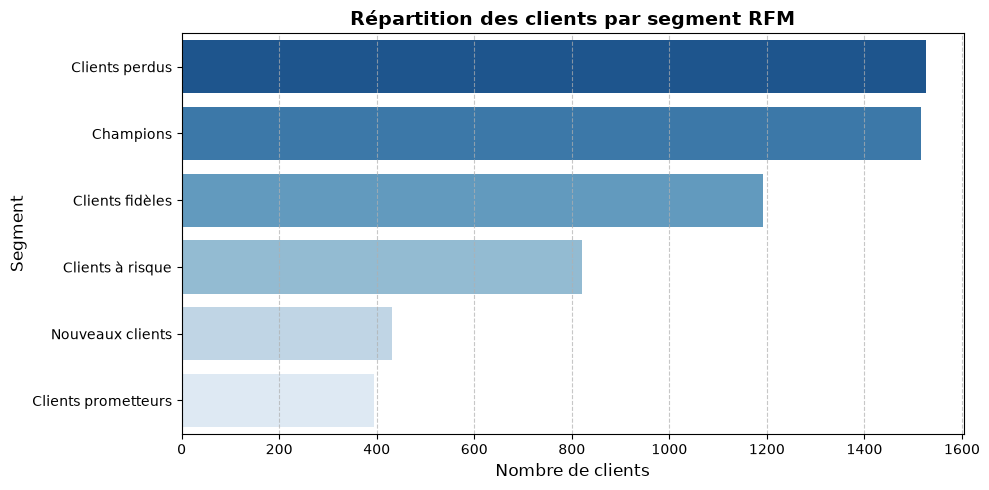

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration du style
plt.figure(figsize=(10, 5))
ordre_segments = rfm['Segment'].value_counts().index

# Barplot horizontal
sns.countplot(data=rfm, y='Segment', order=ordre_segments, palette='Blues_r')

plt.title('Répartition des clients par segment RFM', fontsize=14, weight='bold')
plt.xlabel('Nombre de clients', fontsize=12)
plt.ylabel('Segment', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Section 5 : Analyse des transitions entre segments

## Principe
Pour chaque semestre, on calcule un segment RFM propre à la période. On compare ensuite chaque client actif au semestre de départ à son état au semestre suivant. « Churn » signifie ici qu’il n’a effectué aucun achat pendant le semestre suivant (une réactivation ultérieure reste donc possible). La matrice affiche les probabilités de transition; chaque ligne correspond à un segment de départ et totalise 100 %.

Matrice des probabilités de transition (lignes = 100 %):


Segment_arrivee,Champions,Clients fidèles,Nouveaux clients,Clients à risque,Clients perdus,Clients prometteurs,Churn
Segment_depart,,,,,,,
Champions,28.0%,12.0%,4.1%,10.9%,7.3%,3.1%,34.6%
Clients fidèles,15.7%,11.1%,2.5%,12.2%,4.4%,1.9%,52.1%
Nouveaux clients,7.9%,3.3%,5.4%,3.6%,9.2%,4.1%,66.5%
Clients à risque,13.8%,11.1%,2.4%,11.7%,3.5%,1.3%,56.2%
Clients perdus,7.3%,3.8%,5.8%,3.7%,10.5%,3.6%,65.3%
Clients prometteurs,8.3%,4.6%,3.5%,3.7%,12.3%,4.6%,63.1%


Flux de churn observé par paire de semestres :


,Période,Clients actifs au départ,Clients en churn observé,Taux de churn observé
0,2009-S1 → 2009-S2,427,349,81.7%
1,2009-S2 → 2010-S1,356,142,39.9%
2,2010-S1 → 2010-S2,1754,860,49.0%
3,2010-S2 → 2011-S1,1940,1152,59.4%
4,2011-S1 → 2011-S2,1859,941,50.6%


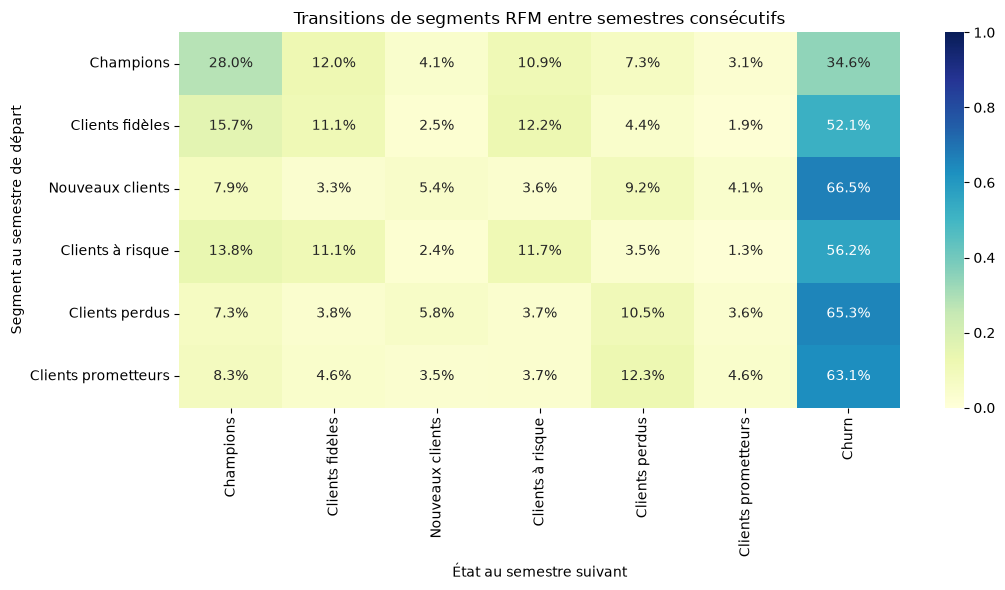

In [59]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Préparer les transactions et repérer les semestres calendaires
transactions = df_clean.copy()
transactions["InvoiceDate"] = pd.to_datetime(
    transactions["InvoiceDate"], dayfirst=True, errors="coerce"
)
transactions = transactions.dropna(subset=["Customer ID", "InvoiceDate", "Invoice"])
transactions["CA"] = pd.to_numeric(
    transactions["Quantity"], errors="coerce"
) * pd.to_numeric(transactions["Price"], errors="coerce")
transactions = transactions.dropna(subset=["CA"])
transactions["Semestre_id"] = (
    transactions["InvoiceDate"].dt.year * 2
    + (transactions["InvoiceDate"].dt.month - 1) // 6
)

noms_segments = [
    "Champions", "Clients fidèles", "Nouveaux clients",
    "Clients à risque", "Clients perdus", "Clients prometteurs"
]


def calculer_rfm_semestre(donnees):
    date_reference = donnees["InvoiceDate"].max() + pd.Timedelta(days=1)
    rfm_semestre = donnees.groupby("Customer ID").agg(
        Recency=("InvoiceDate", lambda dates: (date_reference - dates.max()).days),
        Frequency=("Invoice", "nunique"),
        Monetary=("CA", "sum")
    ).reset_index()

    # Le rang évite les erreurs de qcut lorsque plusieurs clients ont le même score.
    rfm_semestre["R_score"] = pd.qcut(
        rfm_semestre["Recency"].rank(method="first"), 5,
        labels=[5, 4, 3, 2, 1]
    ).astype(int)
    rfm_semestre["F_score"] = pd.qcut(
        rfm_semestre["Frequency"].rank(method="first"), 5,
        labels=[1, 2, 3, 4, 5]
    ).astype(int)
    rfm_semestre["M_score"] = pd.qcut(
        rfm_semestre["Monetary"].rank(method="first"), 5,
        labels=[1, 2, 3, 4, 5]
    ).astype(int)

    def attribuer_segment(ligne):
        r, f = ligne["R_score"], ligne["F_score"]
        if r >= 4 and f >= 4:
            return "Champions"
        if r >= 3 and f >= 3:
            return "Clients fidèles"
        if r >= 4 and f <= 2:
            return "Nouveaux clients"
        if r <= 2 and f >= 3:
            return "Clients à risque"
        if r <= 2 and f <= 2:
            return "Clients perdus"
        return "Clients prometteurs"

    rfm_semestre["Segment"] = rfm_semestre.apply(attribuer_segment, axis=1)
    return rfm_semestre[["Customer ID", "Segment"]]


# Construire l'état RFM de chaque client pour chaque semestre observé.
segments_par_semestre = {}
noms_semestres = {}
for semestre_id, groupe in transactions.groupby("Semestre_id", sort=True):
    annee = int(semestre_id // 2)
    numero_semestre = int(semestre_id % 2) + 1
    nom_semestre = f"{annee}-S{numero_semestre}"
    noms_semestres[semestre_id] = nom_semestre
    segments_par_semestre[semestre_id] = calculer_rfm_semestre(groupe)

# Comparer les clients actifs à chaque paire de semestres consécutifs.
transitions = []
resume_churn = []
semestres_ordonnes = sorted(segments_par_semestre)
for semestre_depart, semestre_arrivee in zip(semestres_ordonnes, semestres_ordonnes[1:]):
    depart = segments_par_semestre[semestre_depart].rename(
        columns={"Segment": "Segment_depart"}
    )
    arrivee = segments_par_semestre[semestre_arrivee].rename(
        columns={"Segment": "Segment_arrivee"}
    )
    comparaison = depart.merge(arrivee, on="Customer ID", how="left")
    comparaison["Segment_arrivee"] = comparaison["Segment_arrivee"].fillna("Churn")
    comparaison["Semestre_depart"] = noms_semestres[semestre_depart]
    comparaison["Semestre_arrivee"] = noms_semestres[semestre_arrivee]
    transitions.append(comparaison)

    nombre_churn = comparaison["Segment_arrivee"].eq("Churn").sum()
    resume_churn.append({
        "Période": f"{noms_semestres[semestre_depart]} → {noms_semestres[semestre_arrivee]}",
        "Clients actifs au départ": len(comparaison),
        "Clients en churn observé": int(nombre_churn),
        "Taux de churn observé": nombre_churn / len(comparaison)
    })

transitions = pd.concat(transitions, ignore_index=True)

# Matrice des effectifs puis probabilités conditionnelles par segment de départ.
matrice_effectifs = pd.crosstab(
    transitions["Segment_depart"], transitions["Segment_arrivee"]
).reindex(index=noms_segments, columns=noms_segments + ["Churn"], fill_value=0)
matrice_effectifs = matrice_effectifs.loc[matrice_effectifs.sum(axis=1) > 0]
matrice_transition = matrice_effectifs.div(matrice_effectifs.sum(axis=1), axis=0)

print("Matrice des probabilités de transition (lignes = 100 %):")
display(matrice_transition.style.format("{:.1%}"))
print("Flux de churn observé par paire de semestres :")
display(pd.DataFrame(resume_churn).style.format({"Taux de churn observé": "{:.1%}"}))

plt.figure(figsize=(11, 6))
sns.heatmap(matrice_transition, annot=True, fmt=".1%", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Transitions de segments RFM entre semestres consécutifs")
plt.xlabel("État au semestre suivant")
plt.ylabel("Segment au semestre de départ")
plt.tight_layout()
plt.show()

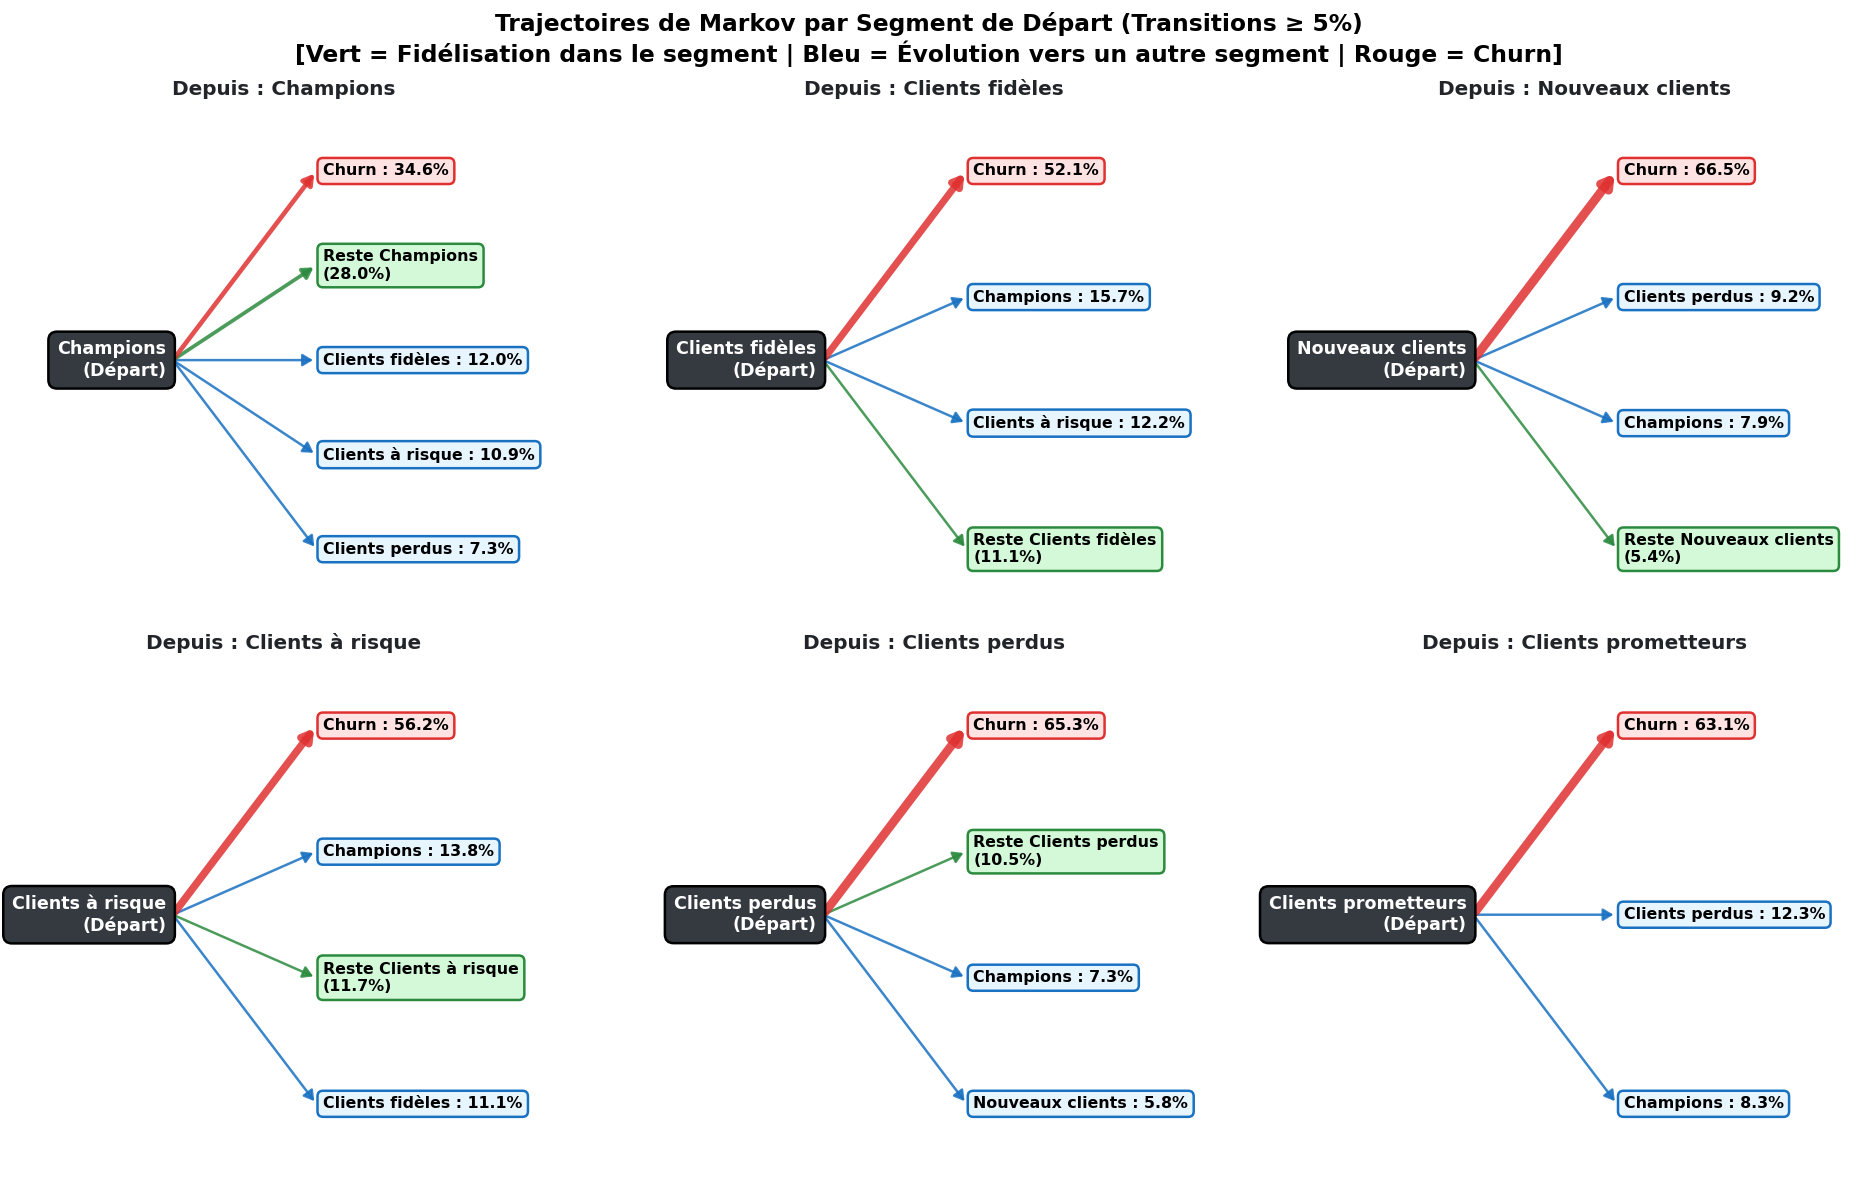

In [10]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Matrice de transition
data = {
    'Champions':           [28.0, 12.0,  4.1, 10.9,  7.3,  3.1, 34.6],
    'Clients fidèles':     [15.7, 11.1,  2.5, 12.2,  4.4,  1.9, 52.1],
    'Nouveaux clients':    [ 7.9,  3.3,  5.4,  3.6,  9.2,  4.1, 66.5],
    'Clients à risque':    [13.8, 11.1,  2.4, 11.7,  3.5,  1.3, 56.2],
    'Clients perdus':      [ 7.3,  3.8,  5.8,  3.7, 10.5,  3.6, 65.3],
    'Clients prometteurs': [ 8.3,  4.6,  3.5,  3.7, 12.3,  4.6, 63.1]
}
cols = ['Champions', 'Clients fidèles', 'Nouveaux clients', 
        'Clients à risque', 'Clients perdus', 'Clients prometteurs', 'Churn']
df_trans = pd.DataFrame.from_dict(data, orient='index', columns=cols)

# 2. Création d'une grille 2x3 (un sous-graphe par segment de départ)
fig, axes = plt.subplots(2, 3, figsize=(16, 10), dpi=120)
axes = axes.flatten()

SEUIL = 5.0  # Affiche toutes les transitions >= 5%

for idx, seg_depart in enumerate(df_trans.index):
    ax = axes[idx]
    G_sub = nx.DiGraph()
    
    # Filtrer les destinations >= SEUIL et trier par probabilité décroissante
    destinations = df_trans.loc[seg_depart]
    dest_filtrees = destinations[destinations >= SEUIL].sort_values(ascending=True)
    
    pos = {'Départ': (0, 0)}
    G_sub.add_node('Départ')
    
    # Placer les destinations en éventail à droite (x = 1)
    y_coords = np.linspace(-1, 1, len(dest_filtrees)) if len(dest_filtrees) > 1 else [0]
    
    for (dest, prob), y in zip(dest_filtrees.items(), y_coords):
        G_sub.add_node(dest)
        G_sub.add_edge('Départ', dest, weight=prob)
        pos[dest] = (1.2, y)
        
        # Couleur selon la destination
        if dest == 'Churn':
            bg, ec = '#ffe3e3', '#e03131'
        elif dest == seg_depart:
            bg, ec = '#d3f9d8', '#2b8a3e'
        else:
            bg, ec = '#e7f5ff', '#1971c2'
            
        # Dessiner la flèche droite avec la probabilité directement dans la boîte d'arrivée
        ax.annotate("", xy=(0.82, y), xytext=(0.18, 0),
                    arrowprops=dict(arrowstyle="-|>,head_width=0.3,head_length=0.5", 
                                    color=ec, lw=max(1.5, prob*0.08), alpha=0.85))
        
        label_dest = f"{dest} : {prob:.1f}%"
        if dest == seg_depart:
            label_dest = f"Reste {dest}\n({prob:.1f}%)"
            
        ax.text(0.85, y, label_dest, ha='left', va='center', fontsize=9.5, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.35', facecolor=bg, edgecolor=ec, lw=1.5))

    # Dessiner le nœud de départ à gauche
    ax.text(0.15, 0, f"{seg_depart}\n(Départ)", ha='right', va='center', fontsize=10.5, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#343a40', edgecolor='black', lw=1.5), color='white')
    
    ax.set_title(f"Depuis : {seg_depart}", fontsize=12, fontweight='bold', color='#212529')
    ax.set_xlim(-0.5, 1.85)
    ax.set_ylim(-1.35, 1.35)
    ax.axis('off')

plt.suptitle("Trajectoires de Markov par Segment de Départ (Transitions ≥ 5%)\n"
             "[Vert = Fidélisation dans le segment | Bleu = Évolution vers un autre segment | Rouge = Churn]", 
             fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()